# 02 - Exploratory Analysis: who says yes, and where do calls stop paying off?

**Business question:** which customers respond to the term-deposit campaign, and how many calls per customer are worth making?

**Rules for this notebook**
- Every chart or table shows the **yes rate of a group and the number of customers in it**. A rate without a group size is not trusted.
- Groups with fewer than 500 customers are flagged as small.
- Differences between groups are *associations*. The data comes from three different years (2008-2010), so I check for mixing before drawing conclusions.
- `duration` is not used anywhere in this notebook.

Input: `Data/bank_clean.csv` (made in `01_data_check`). Charts are saved to `Data/visualizations/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append(".")
from bm_analysis import (AGE_ORDER, MIN_CELL_N, SMALL_N, compare_in_year, fatigue_summary,
                         load_clean, per_call_yield, yes_rate_by)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

IMG_DIR = Path("../Data/visualizations")
IMG_DIR.mkdir(exist_ok=True)

## 0. Load and set up helpers

In [2]:
# load_clean() checks row count, subscriber count, band labels and years, and fails loudly if the CSV was damaged
clean = load_clean()

overall_rate_pct = clean["y_flag"].mean() * 100
print(f"customers: {len(clean):,} | subscribers: {clean['y_flag'].sum():,} | overall yes rate: {overall_rate_pct:.1f}%")

customers: 41,176 | subscribers: 4,639 | overall yes rate: 11.3%


In [3]:
# Chart style: one hue for emphasis, grey for the rest, light grid, no top/right frame.
BAR, HIGHLIGHT, INK, GRID = "#a9bdd3", "#1f5f9f", "#2b3440", "#e3e7ec"

def clean_axes(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK, labelsize=9)
    ax.set_axisbelow(True)

def bar_chart(labels, values, sizes, title, filename, highlight=None, ref_value=None,
              ylabel="Yes rate (%)", horizontal=False, figsize=(8, 4.2)):
    # Tick labels carry the group size so the reader never sees a rate without its n.
    ticks = [f"{l}{'*' if n < SMALL_N else ''}\n(n={n:,})" for l, n in zip(labels, sizes)]
    colors = [HIGHLIGHT if (highlight is not None and h) else BAR for h in (highlight or [False] * len(labels))]
    fig, ax = plt.subplots(figsize=figsize)
    if horizontal:
        pos = np.arange(len(labels))[::-1]
        ax.barh(pos, values, color=colors, height=0.6)
        ax.set_yticks(pos)
        ax.set_yticklabels([t.replace("\n", "  ") for t in ticks])
        ax.xaxis.grid(True, color=GRID)
        ax.set_xlabel(ylabel, color=INK)
        for p, v in zip(pos, values):
            ax.text(v + max(values) * 0.01, p, f"{v:.1f}%", va="center", fontsize=9, color=INK)
        if ref_value is not None:
            ax.axvline(ref_value, color="#6b7785", linestyle="--", linewidth=1)
            ax.text(ref_value, len(labels) - 0.45, f" overall {ref_value:.1f}%", va="bottom", fontsize=8, color="#6b7785")
    else:
        pos = np.arange(len(labels))
        ax.bar(pos, values, color=colors, width=0.6)
        ax.set_xticks(pos)
        ax.set_xticklabels(ticks)
        ax.yaxis.grid(True, color=GRID)
        ax.set_ylabel(ylabel, color=INK)
        for p, v in zip(pos, values):
            ax.text(p, v + max(values) * 0.015, f"{v:.1f}%", ha="center", fontsize=9, color=INK)
        if ref_value is not None:
            ax.axhline(ref_value, color="#6b7785", linestyle="--", linewidth=1)
            ax.text(len(labels) - 0.45, ref_value, f" overall {ref_value:.1f}%", va="bottom", ha="right", fontsize=8, color="#6b7785")
    clean_axes(ax)
    ax.set_title(title, loc="left", fontsize=11, color=INK, fontweight="bold")
    if any(n < SMALL_N for n in sizes):
        fig.text(0.01, 0.005, f"* fewer than {SMALL_N} customers", fontsize=8, color="#6b7785")
    fig.tight_layout()
    fig.savefig(IMG_DIR / filename, dpi=130)
    plt.show()

## 1. Campaign fatigue: how many calls are worth making?

`campaign` is the number of contacts a client received in this campaign, including the last one.

Two views:
1. **By client**: yes rate for clients grouped by how many contacts they received in total.
2. **By call**: yes rate *at* the k-th call = clients who subscribed on call k / clients who were called at least k times. This is the operational view (what does the 4th call return?).

*Assumption for view 2:* a client who subscribes stops being called, so the subscription happened on their last contact (`campaign`). The file does not record the outcome of each individual call, so this cannot be checked directly.

,customers,subscribers,yes_rate_pct,lift_vs_overall,small_group
campaign_band,,,,,
1,17634,2299,13.0,1.15,False
2,10568,1211,11.5,1.02,False
3,5340,574,10.7,0.95,False
4,2650,249,9.4,0.83,False
5,1599,120,7.5,0.67,False
6-7,1608,113,7.0,0.62,False
8-10,908,46,5.1,0.45,False
11+,869,27,3.1,0.28,False


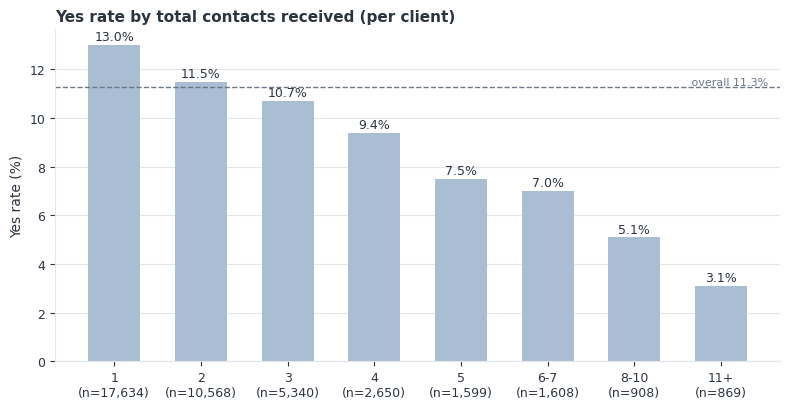

In [4]:
by_client = yes_rate_by(clean, "campaign_band")
display(by_client)
bar_chart(by_client.index.astype(str), by_client["yes_rate_pct"], by_client["customers"],
          "Yes rate by total contacts received (per client)", "02_fatigue_by_client.png",
          ref_value=overall_rate_pct)

,calls_made,subscriptions,yes_rate_pct
call_number,,,
1,41176,2299,5.6
2,23542,1211,5.1
3,12974,574,4.4
4,7634,249,3.3
5,4984,120,2.4
6,3385,75,2.2
7,2406,38,1.6
8,1777,17,1.0
9,1377,17,1.2


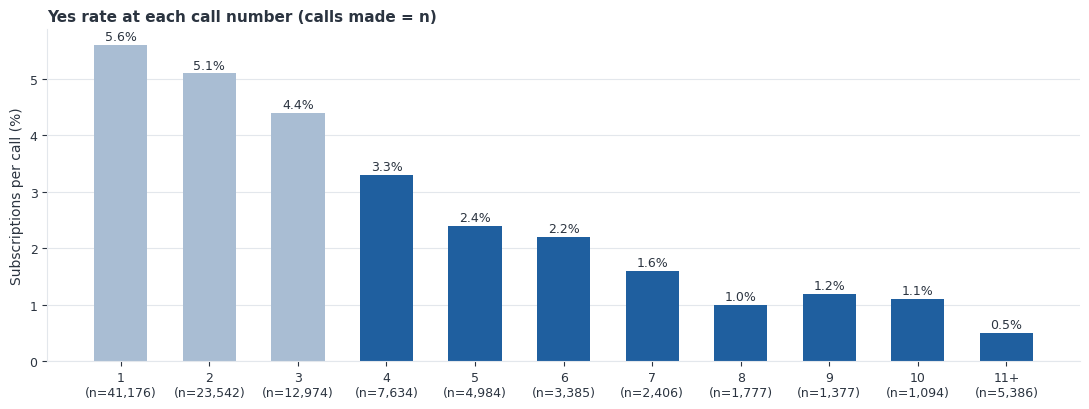

In [5]:
# View 2: yield per call number (vectorised in bm_analysis.per_call_yield; assumption: "yes" happens on the last call)
per_call = per_call_yield(clean)
display(per_call)

bar_chart(per_call.index, per_call["yes_rate_pct"], per_call["calls_made"],
          "Yes rate at each call number (calls made = n)", "02_fatigue_by_call.png",
          highlight=[i >= 3 for i in range(len(per_call))], ylabel="Subscriptions per call (%)",
          figsize=(11, 4.2))   # no overall reference line: the overall 11.3% is per client, this chart is per call

In [6]:
# Operational summary: first three calls vs the 4th call and later
pooled = fatigue_summary(clean).iloc[0]
total_calls, calls_1to3, calls_4plus = int(pooled["total_calls"]), int(pooled["calls_1_to_3"]), int(pooled["calls_4_plus"])
subs_4plus, subs_1to3 = int(pooled["subs_4_plus"]), int(pooled["subs_1_to_3"])

print(f"total calls: {total_calls:,}")
print(f"calls 1-3: {calls_1to3:,} ({calls_1to3 / total_calls:.1%}) -> {subs_1to3:,} subscriptions ({subs_1to3 / calls_1to3:.1%} per call)")
print(f"call 4 and later: {calls_4plus:,} ({calls_4plus / total_calls:.1%}) -> {subs_4plus:,} subscriptions ({subs_4plus / calls_4plus:.1%} per call)")
print(f"share of all subscriptions that came on call 4 or later: {subs_4plus / clean['y_flag'].sum():.1%}")

total calls: 105,735
calls 1-3: 77,692 (73.5%) -> 4,084 subscriptions (5.3% per call)
call 4 and later: 28,043 (26.5%) -> 555 subscriptions (2.0% per call)
share of all subscriptions that came on call 4 or later: 12.0%


**Does fatigue survive a fairness check?** Early years had many more calls than later years and the campaign style may have changed, so I repeat the by-client view inside each year.

In [7]:
fatigue_by_year = (clean.groupby(["campaign_band", "year"], observed=True)["y_flag"]
                   .agg(customers="size", rate="mean").reset_index())
fatigue_by_year["yes_rate_pct"] = (fatigue_by_year["rate"] * 100).round(1)
rate_tbl = fatigue_by_year.pivot(index="campaign_band", columns="year", values="yes_rate_pct")
n_tbl = fatigue_by_year.pivot(index="campaign_band", columns="year", values="customers")
print("yes rate (%) by total contacts and year")
display(rate_tbl)
print("customers in each cell")
display(n_tbl)

yes rate (%) by total contacts and year


year,2008,2009,2010
campaign_band,,,
1,4.9,21.6,52.5
2,4.9,19.4,53.1
3,5.0,19.3,57.2
4,4.8,16.9,45.8
5,4.5,12.0,44.4
6-7,5.1,8.7,40.8
8-10,4.8,6.1,10.0
11+,2.9,6.0,0.0


customers in each cell


year,2008,2009,2010
campaign_band,,,
1,11054,5495,1085
2,7006,3038,524
3,3827,1277,236
4,1904,639,107
5,1144,410,45
6-7,1180,379,49
8-10,750,148,10
11+,817,50,2


**How to read the table above:** inside 2008 the yes rate is almost flat across contact bands, while 2009 shows a clear decline. Most clients with many contacts sit in 2008, which has a much lower yes rate than later years. So the pooled by-client curve is partly produced by *which year* the clients come from. The fairer test of fatigue is the per-call view **inside each year**, done in section 8.

## 2. Previous campaign outcome

`poutcome` = what happened the last time the bank contacted this client. `previously_contacted` was built in `01_data_check` from `previous > 0`.

,customers,subscribers,yes_rate_pct,lift_vs_overall,small_group
poutcome,,,,,
nonexistent,35551,3140,8.8,0.78,False
failure,4252,605,14.2,1.26,False
success,1373,894,65.1,5.78,False


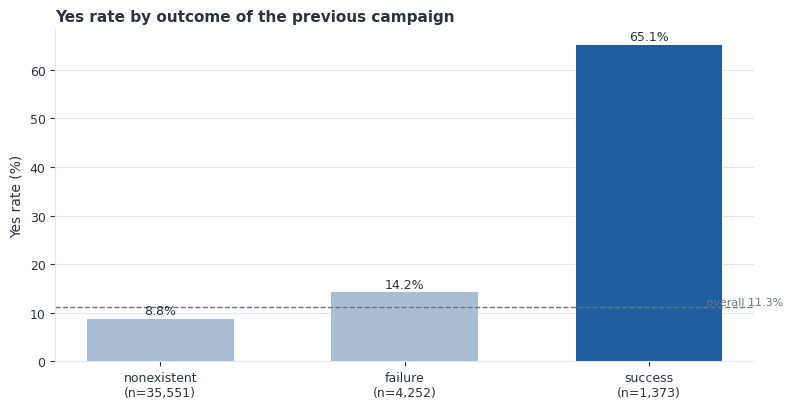

In [8]:
prev = yes_rate_by(clean, "poutcome").loc[["nonexistent", "failure", "success"]]
display(prev)
bar_chart(prev.index, prev["yes_rate_pct"], prev["customers"], "Yes rate by outcome of the previous campaign",
          "02_previous_outcome.png", highlight=[False, False, True], ref_value=overall_rate_pct)

## 3. Contact channel
Cellular vs landline. The channel mix may have changed over time, so I also look at it by year.

,customers,subscribers,yes_rate_pct,lift_vs_overall,small_group
contact,,,,,
cellular,26135,3852,14.7,1.30,False
telephone,15041,787,5.2,0.46,False


customers and yes rate by year and channel


customers           yes_rate_pct          
contact  cellular telephone     cellular telephone
year                                              
2008      13970.0   13712.0          5.7       3.9
2009      10495.0     941.0         19.9      14.7
2010       1670.0     388.0         57.7      28.4

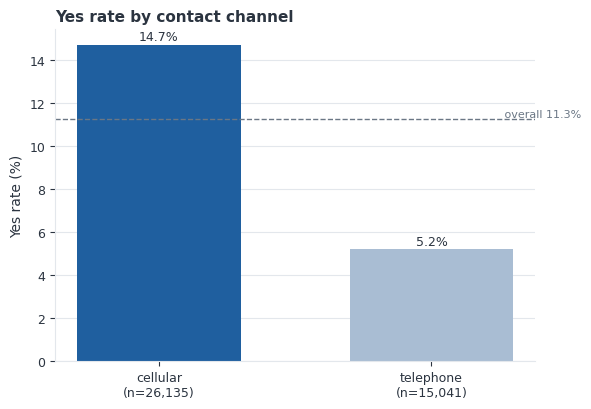

In [9]:
channel = yes_rate_by(clean, "contact")
display(channel)

channel_year = yes_rate_by(clean, ["year", "contact"]).reset_index()
print("customers and yes rate by year and channel")
display(channel_year.pivot(index="year", columns="contact", values=["customers", "yes_rate_pct"]))

bar_chart(channel.index, channel["yes_rate_pct"], channel["customers"], "Yes rate by contact channel",
          "02_contact_channel.png", highlight=[True, False], ref_value=overall_rate_pct, figsize=(6, 4.2))

## 4. Age

,customers,subscribers,yes_rate_pct,lift_vs_overall,small_group
age_band,,,,,
<25,1067,256,24.0,2.13,False
25-29,4600,666,14.5,1.29,False
30-39,16933,1715,10.1,0.90,False
40-49,10523,833,7.9,0.70,False
50-59,6861,697,10.2,0.91,False
60+,1192,472,39.6,3.51,False


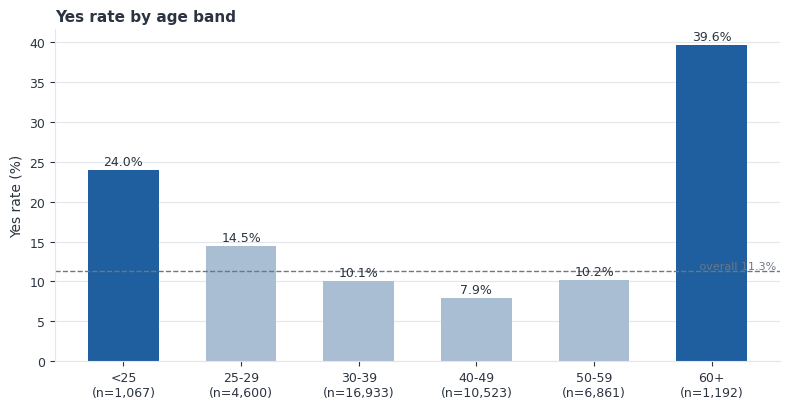

In [10]:
age = yes_rate_by(clean, "age_band")
display(age)
bar_chart(age.index.astype(str), age["yes_rate_pct"], age["customers"], "Yes rate by age band",
          "02_age_band.png", highlight=[(r > 20) for r in age["yes_rate_pct"]], ref_value=overall_rate_pct)

## 5. Job, education, and credit default

,customers,subscribers,yes_rate_pct,lift_vs_overall,small_group
job,,,,,
student,875,275,31.4,2.79,False
retired,1718,434,25.3,2.25,False
unemployed,1014,144,14.2,1.26,False
admin.,10419,1351,13.0,1.15,False
unknown,330,37,11.2,0.99,True
management,2924,328,11.2,0.99,False
technician,6739,730,10.8,0.96,False
self-employed,1421,149,10.5,0.93,False
housemaid,1060,106,10.0,0.89,False


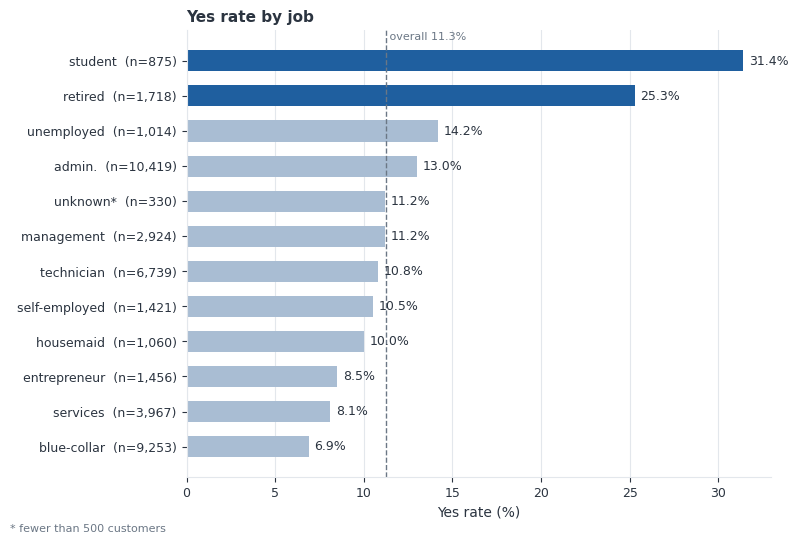

In [11]:
job = yes_rate_by(clean, "job").sort_values("yes_rate_pct", ascending=False)
display(job)
bar_chart(job.index, job["yes_rate_pct"], job["customers"], "Yes rate by job", "02_job.png",
          highlight=[(r > 20) for r in job["yes_rate_pct"]], ref_value=overall_rate_pct, horizontal=True, figsize=(8, 5.4))

In [12]:
edu = yes_rate_by(clean, "education").sort_values("yes_rate_pct", ascending=False)
print("education")
display(edu)
print("credit default (default = yes has very few customers)")
display(yes_rate_by(clean, "default"))

education


,customers,subscribers,yes_rate_pct,lift_vs_overall,small_group
education,,,,,
illiterate,18,4,22.2,1.97,True
unknown,1730,251,14.5,1.29,False
university.degree,12164,1669,13.7,1.22,False
professional.course,5240,595,11.4,1.01,False
high.school,9512,1031,10.8,0.96,False
basic.4y,4176,428,10.2,0.91,False
basic.6y,2291,188,8.2,0.73,False
basic.9y,6045,473,7.8,0.69,False


credit default (default = yes has very few customers)


,customers,subscribers,yes_rate_pct,lift_vs_overall,small_group
default,,,,,
no,32577,4196,12.9,1.15,False
unknown,8596,443,5.2,0.46,False
yes,3,0,0.0,0.00,True


**Job x age band:** does the age effect hold inside job groups, or is it just job mix (students are young, retired are old)? Cells with fewer than 100 customers are left blank.

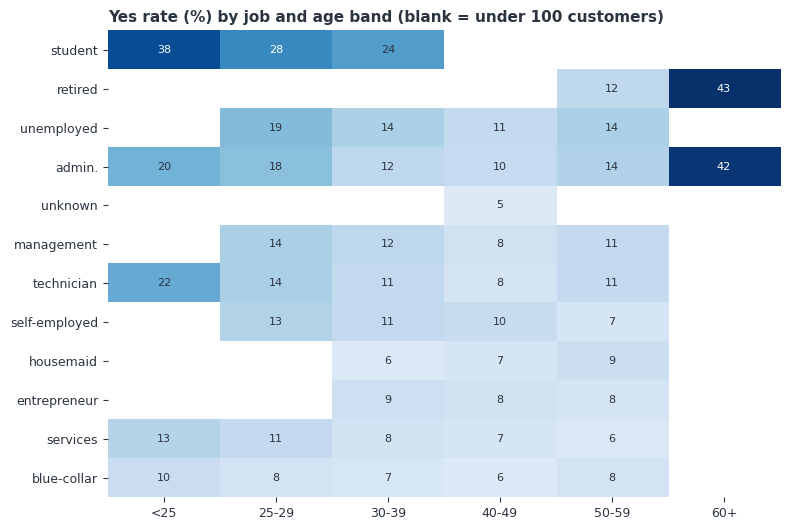

customers behind the heatmap (blank cells above are the small ones)


age_band,<25,25-29,30-39,40-49,50-59,60+
job,,,,,,
student,378.0,304.0,185.0,8.0,NaN,NaN
retired,1.0,3.0,26.0,78.0,826.0,784.0
unemployed,18.0,117.0,415.0,284.0,170.0,10.0
admin.,157.0,1465.0,4892.0,2474.0,1325.0,106.0
unknown,6.0,19.0,73.0,111.0,92.0,29.0
management,27.0,154.0,1072.0,910.0,703.0,58.0
technician,101.0,700.0,3363.0,1620.0,906.0,49.0
self-employed,12.0,173.0,566.0,381.0,268.0,21.0
housemaid,5.0,40.0,313.0,312.0,323.0,67.0


In [13]:
ja = yes_rate_by(clean, ["job", "age_band"]).reset_index()
rate_grid = ja.pivot(index="job", columns="age_band", values="yes_rate_pct")
n_grid = ja.pivot(index="job", columns="age_band", values="customers")
rate_grid = rate_grid.where(n_grid >= MIN_CELL_N)
rate_grid = rate_grid.loc[job.index, AGE_ORDER]          # same job order as the bar chart

fig, ax = plt.subplots(figsize=(8, 5.4))
im = ax.imshow(rate_grid.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(AGE_ORDER))); ax.set_xticklabels(AGE_ORDER)
ax.set_yticks(range(len(rate_grid.index))); ax.set_yticklabels(rate_grid.index)
for i in range(rate_grid.shape[0]):
    for j in range(rate_grid.shape[1]):
        v = rate_grid.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 25 else INK)
ax.set_title(f"Yes rate (%) by job and age band (blank = under {MIN_CELL_N} customers)", loc="left", fontsize=11, color=INK, fontweight="bold")
ax.tick_params(colors=INK, labelsize=9)
for side in ax.spines.values(): side.set_visible(False)
fig.tight_layout()
fig.savefig(IMG_DIR / "02_job_by_age.png", dpi=130)
plt.show()

print("customers behind the heatmap (blank cells above are the small ones)")
display(n_grid.loc[job.index, AGE_ORDER])

## 6. Time: campaign period

Months repeat across years, so the monthly view uses `campaign_period` (YYYY-MM). The lower panel shows how many customers were contacted, because a high rate from a tiny month is not a pattern.

,customers,subscribers,yes_rate_pct,lift_vs_overall,small_group
year,,,,,
2008,27682,1339,4.8,0.43,False
2009,11436,2227,19.5,1.73,False
2010,2058,1073,52.1,4.62,False


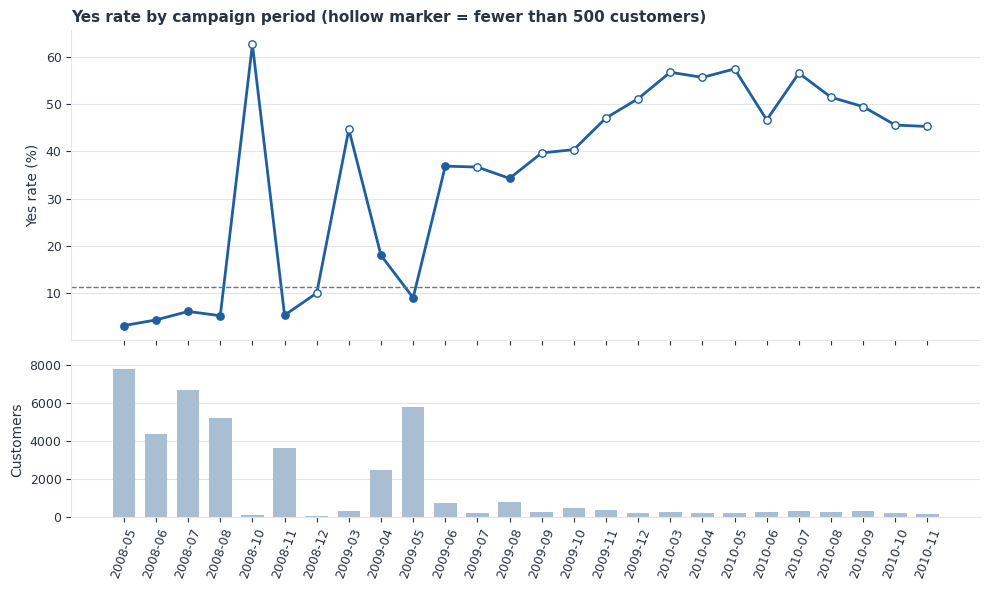

periods with fewer than 500 customers: 2008-10, 2008-12, 2009-03, 2009-07, 2009-09, 2009-10, 2009-11, 2009-12, 2010-03, 2010-04, 2010-05, 2010-06, 2010-07, 2010-08, 2010-09, 2010-10, 2010-11


In [14]:
by_year = yes_rate_by(clean, "year")
display(by_year)

period = yes_rate_by(clean, "campaign_period")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = np.arange(len(period))
ax1.plot(x, period["yes_rate_pct"], color=HIGHLIGHT, linewidth=2)
solid = ~period["small_group"].values
ax1.scatter(x[solid], period["yes_rate_pct"].values[solid], color=HIGHLIGHT, s=28, zorder=3)
ax1.scatter(x[~solid], period["yes_rate_pct"].values[~solid], facecolors="white", edgecolors=HIGHLIGHT, s=28, zorder=3)
ax1.axhline(overall_rate_pct, color="#6b7785", linestyle="--", linewidth=1)
ax1.set_ylabel("Yes rate (%)", color=INK)
ax1.set_title("Yes rate by campaign period (hollow marker = fewer than 500 customers)", loc="left", fontsize=11, color=INK, fontweight="bold")
ax1.yaxis.grid(True, color=GRID); clean_axes(ax1)
ax2.bar(x, period["customers"], color=BAR, width=0.7)
ax2.set_ylabel("Customers", color=INK)
ax2.set_xticks(x); ax2.set_xticklabels(period.index, rotation=70, fontsize=8)
ax2.yaxis.grid(True, color=GRID); clean_axes(ax2)
fig.tight_layout()
fig.savefig(IMG_DIR / "02_campaign_period.png", dpi=130)
plt.show()

print("periods with fewer than", SMALL_N, "customers:", ", ".join(period.index[period["small_group"]]))

In [15]:
dow = yes_rate_by(clean, "day_of_week").loc[["mon", "tue", "wed", "thu", "fri"]]
print("day of week")
display(dow)

day of week


,customers,subscribers,yes_rate_pct,lift_vs_overall,small_group
day_of_week,,,,,
mon,8512,847,10.0,0.89,False
tue,8086,953,11.8,1.05,False
wed,8134,949,11.7,1.04,False
thu,8618,1044,12.1,1.07,False
fri,7826,846,10.8,0.96,False


## 7. Economic context: 3-month Euribor rate

`euribor3m` moves slowly over time, so it is mixed up with the calendar. I show the rate bands and then how the bands are spread across years, to see how much of the pattern is simply "which year".

,customers,subscribers,yes_rate_pct,lift_vs_overall,small_group
euribor_band,,,,,
<1,3907,1786,45.7,4.06,False
1-2,9587,1514,15.8,1.40,False
2+,27682,1339,4.8,0.43,False


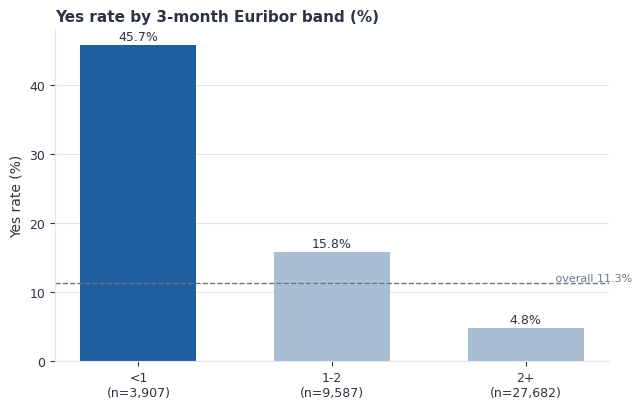

customers by year and Euribor band: how the bands overlap with the calendar


euribor_band,<1,1-2,2+
year,,,
2008,0,0,27682
2009,2048,9388,0
2010,1859,199,0


In [16]:
clean["euribor_band"] = pd.cut(clean["euribor3m"], bins=[0, 1, 2, 10], labels=["<1", "1-2", "2+"])
euri = yes_rate_by(clean, "euribor_band")
display(euri)
bar_chart(euri.index.astype(str), euri["yes_rate_pct"], euri["customers"], "Yes rate by 3-month Euribor band (%)",
          "02_euribor.png", highlight=[True, False, False], ref_value=overall_rate_pct, figsize=(6.5, 4.2))

print("customers by year and Euribor band: how the bands overlap with the calendar")
display(pd.crosstab(clean["year"], clean["euribor_band"]))

## 8. Year check: do the headline findings survive inside each year?

The yes rate is very different from year to year, and the customers in each year are different (channel mix, age mix, number of calls). A pooled number can therefore reflect *when* a customer was called rather than *what kind* of customer it is. For each finding I compare the group with a reference group **within the same year**, and only use years where both groups have at least 100 customers.

In [17]:
display(yes_rate_by(clean, "year"))

mid_age = clean["age_band"].isin(["30-39", "40-49"])
checks = [
    ("previous success vs no previous contact", clean["poutcome"] == "success", clean["poutcome"] == "nonexistent"),
    ("previous failure vs no previous contact", clean["poutcome"] == "failure", clean["poutcome"] == "nonexistent"),
    ("cellular vs telephone", clean["contact"] == "cellular", clean["contact"] == "telephone"),
    ("age 60+ vs age 30-49", clean["age_band"] == "60+", mid_age),
    ("age under 25 vs age 30-49", clean["age_band"] == "<25", mid_age),
    ("retired or student vs other jobs", clean["job"].isin(["retired", "student"]), ~clean["job"].isin(["retired", "student"])),
    ("Euribor below 1% vs 1-2%", clean["euribor_band"] == "<1", clean["euribor_band"] == "1-2"),
]
year_check = pd.concat([compare_in_year(clean, *c) for c in checks], ignore_index=True)
year_check

,customers,subscribers,yes_rate_pct,lift_vs_overall,small_group
year,,,,,
2008,27682,1339,4.8,0.43,False
2009,11436,2227,19.5,1.73,False
2010,2058,1073,52.1,4.62,False


,year,factor,group_n,group_yes_pct,ref_n,ref_yes_pct,ratio,usable
0,2008,previous success vs no previous contact,35,8.6,26948,4.9,1.76,False
1,2009,previous success vs no previous contact,690,56.8,7760,18.7,3.04,True
2,2010,previous success vs no previous contact,648,77.0,843,44.8,1.72,True
3,2008,previous failure vs no previous contact,699,3.4,26948,4.9,0.69,True
4,2009,previous failure vs no previous contact,2986,12.9,7760,18.7,0.69,True
5,2010,previous failure vs no previous contact,567,34.6,843,44.8,0.77,True
6,2008,cellular vs telephone,13970,5.7,13712,3.9,1.46,True
7,2009,cellular vs telephone,10495,19.9,941,14.7,1.35,True
8,2010,cellular vs telephone,1670,57.7,388,28.4,2.03,True
9,2008,age 60+ vs age 30-49,173,5.8,19284,4.8,1.21,True


**Fatigue inside each year (per-call view).** For each year: the yes rate per call on calls 1-3 versus calls 4 and later.

,calls_1_to_3,yield_1_to_3_pct,calls_4_plus,yield_4_plus_pct,share_of_calls_4_plus_pct,ratio_4plus_vs_1to3
year,,,,,,
2008,53932,2.0,23569,1.1,30.4,0.55
2009,20280,10.0,4033,5.0,16.6,0.50
2010,3480,28.2,441,20.4,11.2,0.72


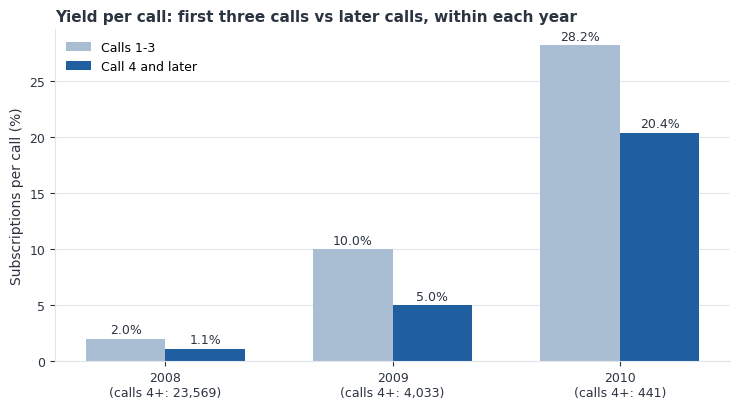

In [18]:
fatigue_year = fatigue_summary(clean, by="year")[
    ["calls_1_to_3", "yield_1_to_3_pct", "calls_4_plus", "yield_4_plus_pct", "share_of_calls_4_plus_pct", "ratio_4plus_vs_1to3"]]
display(fatigue_year)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(len(fatigue_year)); w = 0.35
b1 = ax.bar(x - w / 2, fatigue_year["yield_1_to_3_pct"], w, color=BAR, label="Calls 1-3")
b2 = ax.bar(x + w / 2, fatigue_year["yield_4_plus_pct"], w, color=HIGHLIGHT, label="Call 4 and later")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5, f"{b.get_height():.1f}%", ha="center", fontsize=9, color=INK)
ax.set_xticks(x); ax.set_xticklabels([f"{yr}\n(calls 4+: {n:,})" for yr, n in zip(fatigue_year.index, fatigue_year["calls_4_plus"])])
ax.set_ylabel("Subscriptions per call (%)", color=INK)
ax.yaxis.grid(True, color=GRID); clean_axes(ax)
ax.legend(frameon=False, fontsize=9)
ax.set_title("Yield per call: first three calls vs later calls, within each year", loc="left", fontsize=11, color=INK, fontweight="bold")
fig.tight_layout(); fig.savefig(IMG_DIR / "02_fatigue_by_year.png", dpi=130); plt.show()

In [19]:
# Verdict per finding: in how many usable years does the group beat (or, for fatigue, trail) its reference?
verdicts = []
for name, g in year_check[year_check["usable"]].groupby("factor", sort=False):
    verdicts.append({"finding": name, "usable_years": ", ".join(map(str, g["year"])),
                     "years_group_higher": int((g["ratio"] > 1).sum()), "of_usable_years": len(g),
                     "ratio_by_year": ", ".join(f"{r:.2f}" for r in g["ratio"])})
verdicts.append({"finding": "calls 4+ yield lower than calls 1-3 (per call)", "usable_years": ", ".join(map(str, fatigue_year.index)),
                 "years_group_higher": int((fatigue_year["ratio_4plus_vs_1to3"] < 1).sum()), "of_usable_years": len(fatigue_year),
                 "ratio_by_year": ", ".join(f"{r:.2f}" for r in fatigue_year["ratio_4plus_vs_1to3"])})
verdict_table = pd.DataFrame(verdicts).rename(columns={"years_group_higher": "years_direction_holds"}).set_index("finding")
verdict_table

,usable_years,years_direction_holds,of_usable_years,ratio_by_year
finding,,,,
previous success vs no previous contact,"2009, 2010",2,2,"3.04, 1.72"
previous failure vs no previous contact,"2008, 2009, 2010",0,3,"0.69, 0.69, 0.77"
cellular vs telephone,"2008, 2009, 2010",3,3,"1.46, 1.35, 2.03"
age 60+ vs age 30-49,"2008, 2009, 2010",3,3,"1.21, 2.51, 1.11"
age under 25 vs age 30-49,"2008, 2009, 2010",2,3,"1.31, 1.87, 1.00"
retired or student vs other jobs,"2008, 2009, 2010",3,3,"1.29, 1.95, 1.04"
Euribor below 1% vs 1-2%,"2009, 2010",2,2,"2.63, 1.03"
calls 4+ yield lower than calls 1-3 (per call),"2008, 2009, 2010",3,3,"0.55, 0.50, 0.72"


**How to read the verdict table:** a finding that holds in every usable year is a candidate business rule. A finding that holds in only one year, or whose ratio jumps around, is a calendar effect or a small-group effect and should be written up as a lead, not a rule. The ratio column shows the strength: 1.00 means no difference.

## 8b. Second review: channel inside the same month, and segments inside 2008

An independent review of the draft dashboard raised two points that the by-year check (section 8) does not settle:
1. **Channel.** The first two months of 2008 had no cellular calls at all, so a by-year comparison still mixes different months. I compare cellular and telephone inside the same campaign period, and only where both channels have 100+ customers.
2. **Segments inside 2008.** 2008 holds two-thirds of the customers, so a pooled age or job gap may just be the other two years. I look at the age bands and jobs inside 2008 alone.

This cell is self-contained (it reloads the clean table) and mirrors queries 09 and 12 in `bank_marketing_queries.sql`.

In [20]:
# 1. channel inside the same month, both channels with MIN_CELL_N+ customers
t = clean.groupby(["campaign_period", "contact"])["y_flag"].agg(n="size", rate="mean").unstack()
ok = (t[("n", "cellular")] >= MIN_CELL_N) & (t[("n", "telephone")] >= MIN_CELL_N)
cmp = pd.DataFrame({"cellular_n": t.loc[ok, ("n", "cellular")], "cellular_yes_pct": (t.loc[ok, ("rate", "cellular")] * 100).round(1),
                    "telephone_n": t.loc[ok, ("n", "telephone")], "telephone_yes_pct": (t.loc[ok, ("rate", "telephone")] * 100).round(1)})
cmp["cellular_higher"] = cmp["cellular_yes_pct"] > cmp["telephone_yes_pct"]
print(cmp.to_string())
print(f"Cellular is higher in {int(cmp['cellular_higher'].sum())} of {len(cmp)} comparable months.")
print("Months with no cellular calls at all:", ", ".join(t.index[t[("n", "cellular")].isna()]))

# 2. segments inside 2008
in_2008 = clean[clean["year"] == 2008]
age8 = yes_rate_by(in_2008, "age_band")[["customers", "yes_rate_pct"]].rename(columns={"yes_rate_pct": "yes_pct"})
job8 = yes_rate_by(in_2008, "job")[["customers", "yes_rate_pct"]].rename(columns={"yes_rate_pct": "yes_pct"})
print("\n2008 age bands:"); print(age8.to_string())
print(f"\n2008 age bands range {age8['yes_pct'].min()}-{age8['yes_pct'].max()}%; jobs range {job8['yes_pct'].min()}-{job8['yes_pct'].max()}%")

                 cellular_n  cellular_yes_pct  telephone_n  telephone_yes_pct  cellular_higher
campaign_period                                                                               
2008-07              5693.0               6.6        988.0                2.9             True
2008-08              5026.0               5.2        147.0                8.2            False
2008-11              3248.0               5.0        367.0                7.4            False
2009-04              2293.0              18.1        164.0               15.9             True
2009-05              5346.0               9.5        447.0                4.0             True
Cellular is higher in 3 of 5 comparable months.
Months with no cellular calls at all: 2008-05, 2008-06

2008 age bands:
          customers  yes_pct
age_band                    
<25             397      6.3
25-29          2602      5.3
30-39         11439      5.2
40-49          7845      4.3
50-59          5226      4.6
60+         

**Finding (8b).** Inside the same month, cellular is higher in some months and lower in others, so the clean 'cellular beats telephone' reading from the pooled and by-year tables does not survive. Treat the channel as unproven: part of the pooled gap is *when* each channel was used. Inside 2008 every age band and job sits within a narrow band, so the large pooled age and job gaps come mostly from 2009 and 2010. The numbers above are the evidence; the recommendations below are written with that in mind.

## 9. Key facts (computed from the data above)

In [21]:
facts = []
facts.append(f"Overall: {len(clean):,} customers, yes rate {overall_rate_pct:.1f}%.")
yr = by_year["yes_rate_pct"]
facts.append(f"Calendar dominates: the yes rate is {yr.loc[2008]}% in 2008, {yr.loc[2009]}% in 2009 and {yr.loc[2010]}% in 2010, and {by_year.loc[2008, 'customers'] / len(clean):.0%} of customers were contacted in 2008.")

fy = fatigue_year
facts.append("Fatigue (per call, inside each year): calls 4+ return "
             + ", ".join(f"{fy.loc[y, 'yield_4_plus_pct']}% vs {fy.loc[y, 'yield_1_to_3_pct']}% in {y}" for y in fy.index)
             + f". Pooled: calls 4+ are {calls_4plus / total_calls:.1%} of all calls and produced {subs_4plus / clean['y_flag'].sum():.1%} of subscriptions.")

s = prev.loc["success"]
facts.append(f"Previous success: {s['yes_rate_pct']}% yes pooled ({int(s['customers']):,} customers, {s['lift_vs_overall']}x overall); pooled lift is inflated by calendar mixing, see the verdict table.")
fail = year_check[(year_check["factor"] == "previous failure vs no previous contact") & year_check["usable"]]
facts.append(f"Previous failure: pooled {prev.loc['failure', 'yes_rate_pct']}% vs {prev.loc['nonexistent', 'yes_rate_pct']}% for never-contacted, which looks better, but inside each year failures convert at {fail['ratio'].min():.2f}-{fail['ratio'].max():.2f}x the never-contacted rate. The pooled gap is a year-mix effect (failures are mostly 2009-2010 customers).")
facts.append(f"Channel: cellular {channel.loc['cellular', 'yes_rate_pct']}% vs telephone {channel.loc['telephone', 'yes_rate_pct']}% pooled.")
big_jobs = job[job["customers"] >= SMALL_N]
facts.append(f"Jobs (groups of {SMALL_N}+, pooled): highest {big_jobs['yes_rate_pct'].idxmax()} {big_jobs['yes_rate_pct'].max()}%, lowest {big_jobs['yes_rate_pct'].idxmin()} {big_jobs['yes_rate_pct'].min()}%.")
facts.append(f"Age (pooled): youngest band {age['yes_rate_pct'].iloc[0]}% (n={int(age['customers'].iloc[0]):,}), oldest {age['yes_rate_pct'].iloc[-1]}% (n={int(age['customers'].iloc[-1]):,}), middle bands {age['yes_rate_pct'].iloc[2:5].min()}-{age['yes_rate_pct'].iloc[2:5].max()}%.")
facts.append(f"Euribor (pooled): below 1% -> {euri.loc['<1', 'yes_rate_pct']}% vs {euri.loc['2+', 'yes_rate_pct']}% at 2% or above; the 2%+ band is exactly the 2008 customers, so it cannot be separated from the year.")
facts.append(f"Day of week: yes rate only ranges {dow['yes_rate_pct'].min()}-{dow['yes_rate_pct'].max()}%.")
for f in facts:
    print("-", f)

- Overall: 41,176 customers, yes rate 11.3%.
- Calendar dominates: the yes rate is 4.8% in 2008, 19.5% in 2009 and 52.1% in 2010, and 67% of customers were contacted in 2008.
- Fatigue (per call, inside each year): calls 4+ return 1.1% vs 2.0% in 2008, 5.0% vs 10.0% in 2009, 20.4% vs 28.2% in 2010. Pooled: calls 4+ are 26.5% of all calls and produced 12.0% of subscriptions.
- Previous success: 65.1% yes pooled (1,373 customers, 5.78x overall); pooled lift is inflated by calendar mixing, see the verdict table.
- Previous failure: pooled 14.2% vs 8.8% for never-contacted, which looks better, but inside each year failures convert at 0.69-0.77x the never-contacted rate. The pooled gap is a year-mix effect (failures are mostly 2009-2010 customers).
- Channel: cellular 14.7% vs telephone 5.2% pooled.
- Jobs (groups of 500+, pooled): highest student 31.4%, lowest blue-collar 6.9%.
- Age (pooled): youngest band 24.0% (n=1,067), oldest 39.6% (n=1,192), middle bands 7.9-10.2%.
- Euribor (pooled)

## 10. Caveats to carry into the SQL, Power BI and README

- **The calendar year is the biggest driver in the data.** Yes rates differ enormously between 2008, 2009 and 2010, and most customers are from 2008. The file does not say why (a change in who was called, the product, the economy, or how the campaign was run), so I cannot name a cause.
- **Pooled numbers can mislead.** Use the within-year comparisons (section 8) before making a recommendation. Every Power BI view of a segment should have a year slicer.
- **Group size:** the highest rates (oldest and youngest age bands, some months, 2010) come from small groups. Always show n next to the rate.
- **Simpson's paradox appears in the previous-campaign result.** Pooled, clients who failed a previous campaign look *better* than never-contacted clients; inside every year they look *worse*. Always read pooled gaps next to the within-year check.
- **Euribor and month effects are not separable from the year**, so they are shown as context only.
- **Fatigue per call** rests on the assumption that a subscription happens on the client's last contact. It also has a survivor effect: clients who say yes stop being called, so customers who reach call 5 are, by construction, people who kept saying no.
- **Channel is confounded with timing.** Cellular was not used at all in May-June 2008, and inside the same month the direction is mixed (section 8b). Do not present 'cellular beats telephone' as a finding.
- **Segment gaps are mostly a 2009-2010 story.** Inside 2008 (two-thirds of customers) age bands and jobs are all within a narrow range (section 8b).
- **Not a Thai market result.** Portuguese bank, 2008-2010.

## 11. What this suggests for the business (draft, to be tested in SQL)
1. **Review repeat calling after the 3rd contact.** Later calls return clearly less per call in every year (see the verdict table for the size).
2. **Call previous-campaign successes first.** The channel result is mixed inside a month (section 8b), so do not recommend a channel.
3. **Treat age, job and economic findings as leads, not targeting rules.** They are strong in some years and absent in others, so confirm them in SQL with a year filter before they go into a recommendation.
4. **Use "what-if" language for savings.** The file has no call cost, so any saving is an assumption that has to be labelled as one.